# Ranker 独立微调：样本、训练、评估与推理

[English](01_finetune.ipynb) | 简体中文

## Goal
仅使用 ranker 配置、预生成文本对和外部候选文件完成 CrossEncoder 微调。训练、评估和推理均无需加载 embedding。默认随机 tiny BERT 与合成数据验证完整流程，指标不能代表业务效果。

## Setup
安装 `python -m pip install -e '.[ranker,notebooks]'`。Colab 放置仓库后使用 `%pip install -e '/content/advai-notebooks[ranker,notebooks]'` 并配置 ROOT。

In [1]:
from pathlib import Path
import sys
import importlib.metadata

# Colab: set ROOT = Path("/content/advai-notebooks") after placing the repo there.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "pyproject.toml").exists()), None)
if ROOT is None:
    raise RuntimeError("Set ROOT to the repository directory before continuing")
sys.path.insert(0, str(ROOT / "src"))
for name in ["torch", "transformers", "sentence-transformers"]:
    print(name, importlib.metadata.version(name))
print("Repository:", ROOT)
from huggingface_hub.utils import disable_progress_bars
from transformers.utils.logging import disable_progress_bar
disable_progress_bars()
disable_progress_bar()

torch 2.14.0
transformers 5.18.0
sentence-transformers 5.7.0
Repository: /Users/xuyi/Documents/workspace/advai-notebooks


## Step 1 — Ranker 配置与数据
训练样本是 `{query_id, doc_id, label}`，正例 label=1，负例 label=0；候选文件提供 validation/test 的查询与文档 ID、原始得分。默认示例文件已准备好，也可从外部检索系统生成。

数据准备有单独的 `advai-data prepare` 入口；负例来源不属于 ranker 的训练配置。

In [2]:
import tempfile
from advai_notebooks.ranker.config import load_config
from advai_notebooks.ranker.data import load_training_samples, load_evaluation_candidates
from advai_notebooks.common.retrieval_data import load_data

CONFIG = ROOT / "configs/ranker/smoke.yaml"  # Domain data: configs/ranker/bge.yaml
cfg = load_config(CONFIG, root=ROOT)
parent = ROOT / "outputs/ranker"
parent.mkdir(parents=True, exist_ok=True)
RUN_DIR = Path(tempfile.mkdtemp(prefix="notebook-", dir=parent)) / "run"
cfg.output_dir = str(RUN_DIR)
data = load_data(cfg)
pairs, samples_fingerprint = load_training_samples(cfg, data)
candidates = load_evaluation_candidates(cfg, data)
print(data.summary())
print("Training pairs:", len(pairs), "First pairs:", pairs[:3])
print("Candidate queries:", {s: len(rows) for s, rows in candidates.items()})
print("Run:", RUN_DIR)

{'documents': 12, 'queries': 18, 'judgments': 216, 'queries_by_split': {'train': 12, 'validation': 3, 'test': 3}, 'fingerprint': 'f96589e88e79ce684f3c8733ae1a3c98a8f028459f6e82e3477efeb2867b2a19', 'document_group_isolation': True}
Training pairs: 48 First pairs: [{'query_id': 'crash-0', 'doc_id': 'crash-guide', 'label': 1.0}, {'query_id': 'crash-0', 'doc_id': 'crash-help', 'label': 1.0}, {'query_id': 'crash-0', 'doc_id': 'invoice-guide', 'label': 0.0}]
Candidate queries: {'validation': 3, 'test': 3}
Run: /Users/xuyi/Documents/workspace/advai-notebooks/outputs/ranker/notebook-nwv20kw8/run


## Step 2 — 独立训练与验证集选择
使用 BCEWithLogitsLoss，采样与 loss 在 ranker 自己的模块中。验证候选文件不会在训练期间重新召回；缺失正例保持缺失。按验证指标选择 best，包括 epoch 0 的基线。测试集不用于选模型。

In [3]:
from advai_notebooks.ranker.pipeline import run
report = run(cfg)
print("Selected epoch:", report["training"]["best_epoch"])
print("Export:", report["export"])

ranker: epoch 1, loss=0.6940, validation mrr@3=0.0000


ranker: epoch 2, loss=0.6933, validation mrr@3=0.0000


Selected epoch: 0
Export: /Users/xuyi/Documents/workspace/advai-notebooks/outputs/ranker/notebook-nwv20kw8/run/export


## Checks — 候选一致性与训练轨迹
所有 baseline/selected 排序均使用原始候选文档集合。Recall 分母包含全部已知正例，nDCG 保留相关性等级。BCE 使用二分类标签，输出 logit 尚未校准为概率。

Checkpoint,recall@3,mrr@3,ndcg@3
Original candidates,0.0000,0.0000,0.0000
Baseline ranker,0.0000,0.0000,0.0000
Selected ranker,0.0000,0.0000,0.0000


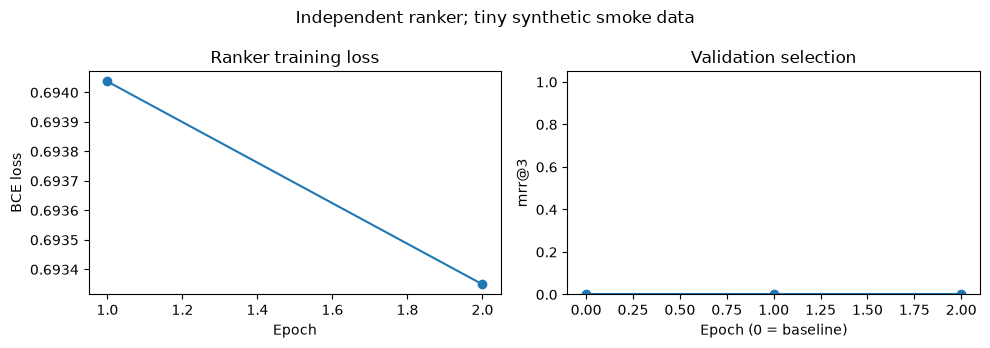

Candidate membership checks passed.


In [4]:
import json
import math
from IPython.display import display, HTML
import matplotlib.pyplot as plt

saved_candidates = json.loads((RUN_DIR / "candidates.json").read_text())["splits"]["test"]
rankings = json.loads((RUN_DIR / "test_rankings.json").read_text())
for qid, rows in saved_candidates.items():
    ids = {r["doc_id"] for r in rows}
    assert ids == {r["doc_id"] for r in rankings["baseline"][qid]}
    assert ids == {r["doc_id"] for r in rankings["finetuned"][qid]}
K = 3 if 3 in cfg.evaluation.cutoffs else cfg.evaluation.cutoffs[0]
keys = [f"{m}@{K}" for m in ["recall", "mrr", "ndcg"]]
html = "<table><tr><th>Checkpoint</th>" + "".join(f"<th>{k}</th>" for k in keys) + "</tr>"
for label, field in [("Original candidates", "retrieval_test"), ("Baseline ranker", "baseline_test"), ("Selected ranker", "finetuned_test")]:
    html += f"<tr><td>{label}</td>" + "".join(f"<td>{report[field]['metrics'][k]:.4f}</td>" for k in keys) + "</tr>"
display(HTML(html + "</table>"))
history = report["training"]["history"]
assert all(math.isfinite(h["train_loss"]) for h in history[1:])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot([h["epoch"] for h in history[1:]], [h["train_loss"] for h in history[1:]], marker="o")
axes[0].set(xlabel="Epoch", ylabel="BCE loss", title="Ranker training loss")
metric = cfg.evaluation.selection_metric
axes[1].plot([h["epoch"] for h in history], [h["validation"][metric] for h in history], marker="o")
axes[1].set(xlabel="Epoch (0 = baseline)", ylabel=metric, title="Validation selection", ylim=(0, 1.05))
fig.suptitle("Independent ranker; tiny synthetic smoke data")
fig.tight_layout()
fig.savefig(RUN_DIR / "training.png", dpi=130)
plt.show()
print("Candidate membership checks passed.")

## Step 3 — 推理与原生 SDK 一致性
加载 export 后直接给 query/document 文本对打分。预处理前缀由 wrapper 应用；用 SDK 时先处理前缀，指定 Identity 激活取得原始 logit。这里不调用检索器。

In [5]:
import numpy as np
import torch
from sentence_transformers import CrossEncoder
from advai_notebooks.ranker.model import RankerModel

model = RankerModel.load(report["export"], device="cpu")
sdk = CrossEncoder(report["export"], device="cpu")
inputs = [("reset password", "account login password reset"),
          ("reset password", "payment invoice refund")]
model.check_lengths(inputs)
scores = model.score(inputs)
expected = sdk.predict(model.prepare(inputs), activation_fn=torch.nn.Identity(), show_progress_bar=False).reshape(-1)
np.testing.assert_allclose(scores, expected, atol=1e-6)
print("Reload and native SDK agreement passed.")
for pair, score in sorted(zip(inputs, scores), key=lambda item: -item[1]):
    print(f"{score:.5f}", pair)
print("Report:", RUN_DIR / "report.json")

Reload and native SDK agreement passed.
0.01315 ('reset password', 'account login password reset')
0.01310 ('reset password', 'payment invoice refund')
Report: /Users/xuyi/Documents/workspace/advai-notebooks/outputs/ranker/notebook-nwv20kw8/run/report.json


## Next Steps
- 替换 ranker 自己的基座、数据、采样或 loss；修改 `ranker/config.py`、`data.py`、`sampling.py`、`losses.py`、`train.py` 中对应模块。
- 用现实数据与固定外部候选评估；候选可来自已有 embedding、关键词检索、人工整理等系统。
- 需要组合对照时运行 `notebooks/workflows/01_retrieval_comparison.ipynb`；这是可选流程。

当前单设备全参数训练已支持完整 epoch 的 optimizer/scaler/RNG 恢复。使用原配置和 `--resume <output_dir>/latest`；推理导出本身不能恢复训练。配置、数据或源码改变应创建新实验。真实模型、CUDA/MPS 的效果与资源需在目标硬件验证。

## 可选：发布到 Hugging Face

将 `REPO_ID` 改为自己的 `namespace/model`。默认 `UPLOAD_TO_HUB = False`，只离线验证发布包并保存清单；设置为 `True` 后才实际上传。实际上传前通过 `hf auth login` 或 `HF_TOKEN` 配置认证。仓库默认私有，许可证由使用者明确指定。详细说明见 [发布指南](../../docs/publishing.zh-CN.md)。

In [6]:
from advai_notebooks.ranker.publish import publish
from advai_notebooks.common.artifacts import write_json

REPO_ID = "your-org/your-ranker"
UPLOAD_TO_HUB = False
PUBLIC = False
LICENSE = None
publication = publish(
    report["export"], REPO_ID,
    private=not PUBLIC, license=LICENSE, dry_run=not UPLOAD_TO_HUB,
)
publication_path = RUN_DIR / "publication.json"
write_json(publication_path, publication)
print("Publication:", publication["status"])
print("Files:", [row["path"] for row in publication["files"]])
print("Result / preview:", publication_path)
if publication.get("commit"):
    print("Pin this revision:", publication["commit"])

Publication: dry_run
Files: ['README.md', 'advai_metadata.json', 'config.json', 'config_sentence_transformers.json', 'model.safetensors', 'modules.json', 'sentence_bert_config.json', 'tokenizer.json', 'tokenizer_config.json']
Result / preview: /Users/xuyi/Documents/workspace/advai-notebooks/outputs/ranker/notebook-nwv20kw8/run/publication.json
